# County unemployment early warning: the final model and conclusions

**Question (same as notebooks 01 and 02):** for a county in month *t*, will its unemployment rate rise by **≥ 0.5 percentage points
over the next 3 months** (`y_label` in `marts.county_month`)?

This notebook closes the modeling work. It
1. rebuilds the **same data design** as notebooks 01 and 02,
2. lists every model tried so far and which ones can be built from the `county_month` mart alone,
3. compares the finalists head-to-head on the out-of-time test year,
4. **declares the best model**, with the reasons, caveats, and places to improve,
5. sums up what the three notebooks found.

Nothing is saved or written anywhere; the notebook only reads the mart.

In [1]:
import os, time, warnings
import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict, train_test_split
from sklearn.metrics import (roc_auc_score, average_precision_score, log_loss, brier_score_loss,
                             accuracy_score, precision_score, recall_score, f1_score, precision_recall_curve)
from sklearn.calibration import CalibrationDisplay
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:.4f}".format)
RNG = 42

## 1. Same data as notebooks 01 and 02

Same loading, same seasonal-naive baseline, same out-of-time test year with its 3-month gap, and the same stratified 60k tuning sample
and quarter-grouped folds (same seeds). The assert checks that the split matches the earlier notebooks.

In [2]:
if os.environ.get("MOTHERDUCK_TOKEN"):
    con = duckdb.connect("md:unemployment")
    df = con.sql("select * from marts.county_month order by county_fips, month").df()
    con.close()
    source = "MotherDuck: unemployment.marts.county_month"
else:
    df = pd.read_parquet("data/county_month.parquet").sort_values(["county_fips", "month"])
    source = "data/county_month.parquet"
df["month"] = pd.to_datetime(df["month"])
FEATURES = [c for c in df.columns if c.startswith("f_")]

# seasonal-naive score: the county's change over the same 3-month window last year (backward-looking only)
df["m_idx"] = df.month.dt.year * 12 + df.month.dt.month
key = df[["county_fips", "m_idx", "f_rate"]]
n_before = len(df)
for lag in [9, 12]:
    df = df.merge(key.assign(m_idx=key.m_idx + lag).rename(columns={"f_rate": f"rate_tm{lag}"}), on=["county_fips", "m_idx"], how="left")
assert len(df) == n_before, "merge changed the row count"
df["seasonal_naive_delta"] = df.rate_tm9 - df.rate_tm12

lab = df[df["is_labeled"]].copy(); lab["y"] = lab["y_label"].astype(int)
lab_months = np.sort(lab.month.unique())
test_start, gap_start = lab_months[-12], lab_months[-15]
train = lab[lab.month < gap_start].copy()
test = lab[lab.month >= test_start].copy()
assert len(train) == 377_097 and len(test) == 37_716, "split differs from notebook 01 (data changed?)"

X_cols = FEATURES
tune, _ = train_test_split(train, train_size=60_000, stratify=train.y, random_state=RNG)
groups_tune = (tune.month.dt.year * 10 + tune.month.dt.quarter).values
X_train, y_train = train[X_cols], train.y.values
X_test, y_test = test[X_cols], test.y.values
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RNG)

print(f"source: {source}")
print(f"train {len(train):,} rows ({train.month.min():%Y-%m} to {train.month.max():%Y-%m}), positive rate {y_train.mean():.3f}")
print(f"test  {len(test):,} rows ({test.month.min():%Y-%m} to {test.month.max():%Y-%m}), positive rate {y_test.mean():.3f}")
print(f"tune  {len(tune):,} rows, positive rate {tune.y.mean():.3f}")

source: MotherDuck: unemployment.marts.county_month
train 377,097 rows (2015-01 to 2024-12), positive rate 0.273
test  37,716 rows (2025-04 to 2026-05), positive rate 0.288
tune  60,000 rows, positive rate 0.273


## 2. Everything tried so far, and what can be built from the mart

The pipeline's output is one table, the `county_month` mart, and its features are the `f_` columns. A model counts as **usable
as-is** only if every input it needs is an `f_` column in the mart; anything else needs a pipeline change first. Test-year results from the earlier notebooks:

| Model (notebook) | Test ROC AUC | Test F1 | Usable as-is? |
|---|---|---|---|
| Seasonal-naive rule (01) | – (no score) | 0.667 | not a model; the bar to beat |
| LR, elastic net ρ = 0.25, C = 0.1, all training years (01) | 0.799 | 0.59 | **yes** |
| LR, same settings, trained **without 2020–21** (01 §5.5) | 0.827 | 0.64 | **yes** (only the training rows change) |
| LR on PCA (11 components) / on UMAP-10 (01) | 0.65 / 0.41 | – | yes, but clearly worse |
| Linear SVM / RBF / polynomial / sigmoid SVM (02) | 0.782 / 0.784 / 0.774 / 0.725 | 0.52–0.57 | yes, but every one is significantly below LR |
| **LR + two county seasonal features, without 2020–21** (02 §7) | **0.861** | **0.68** | **no**: `x_seas_chg_1y` / `x_seas_chg_2y` are computed in notebook 02, not in the mart |

Two conclusions follow before running anything:
- **Logistic regression is the model family.** SVMs never beat it on the test year, cost far more to fit, and need a separate
  calibration step to produce probabilities.
- The overall best result (LR + seasonal features) **isn't usable as-is**: its two features aren't in the mart. Among the usable models,
  the choice is between LR trained on all years and LR trained without 2020–21. The next section re-checks that comparison carefully.

## 3. The finalists head-to-head on the test year

Both finalists use notebook 01's tuned settings (elastic net ρ = 0.25, C = 0.1). Each one's F1 threshold is chosen from **out-of-fold
predictions on the tuning sample** (the threshold is treated as a hyperparameter), using the same rows each model is trained on:
for the no-COVID model, tuning rows from 2020–21 are left out too. The test year is touched only to score.

In [3]:
def make_lr(C=0.1, l1_ratio=0.25):
    return Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler()),
                     ("lr", LogisticRegression(C=C, l1_ratio=l1_ratio, solver="saga", max_iter=3000, tol=1e-3, random_state=RNG))])

def f1_threshold(y, p):
    prec, rec, thr = precision_recall_curve(y, p)
    f1s = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
    return float(thr[np.argmax(f1s)])

def evaluate(name, y_true, p=None, yhat=None, thr=None):
    if yhat is None:
        yhat = (p >= thr).astype(int)
    has_p = p is not None
    return {"model": name, "threshold": thr,
            "log_loss": log_loss(y_true, p) if has_p else np.nan, "brier": brier_score_loss(y_true, p) if has_p else np.nan,
            "roc_auc": roc_auc_score(y_true, p) if has_p else np.nan, "pr_auc": average_precision_score(y_true, p) if has_p else np.nan,
            "accuracy": accuracy_score(y_true, yhat), "precision": precision_score(y_true, yhat, zero_division=0),
            "recall": recall_score(y_true, yhat), "f1": f1_score(y_true, yhat)}

no_covid = lambda d: ~d.month.dt.year.isin([2020, 2021]).values
finalists = {"LR, all training years": (np.ones(len(train), bool), np.ones(len(tune), bool)),
             "LR, without 2020–21": (no_covid(train), no_covid(tune))}

rows, probs, thresholds = [], {}, {}
p_dummy = DummyClassifier(strategy="prior").fit(X_train, y_train).predict_proba(X_test)[:, 1]
rows.append(evaluate("Dummy (prior)", y_test, p_dummy, thr=0.5))
rows.append(evaluate("Seasonal-naive rule", y_test, yhat=(test.seasonal_naive_delta.fillna(0).values >= 0.5).astype(int)))
for name, (keep_tr, keep_tu) in finalists.items():
    t0 = time.time()
    oof = cross_val_predict(make_lr(), tune.loc[keep_tu, X_cols], tune.y.values[keep_tu], cv=cv, groups=groups_tune[keep_tu],
                            method="predict_proba", n_jobs=-1)[:, 1]
    thresholds[name] = f1_threshold(tune.y.values[keep_tu], oof)
    probs[name] = make_lr().fit(X_train[keep_tr], y_train[keep_tr]).predict_proba(X_test)[:, 1]
    rows.append(evaluate(name, y_test, probs[name], thr=thresholds[name]))
    print(f"{name}: {keep_tr.sum():,} training rows, threshold {thresholds[name]:.3f}, {time.time() - t0:.0f}s")

results = pd.DataFrame(rows).set_index("model")
results.style.format("{:.4f}", na_rep="–").highlight_min(subset=["log_loss", "brier"], color="#d4edda") \
    .highlight_max(subset=["roc_auc", "pr_auc", "accuracy", "precision", "recall", "f1"], color="#d4edda")

LR, all training years: 377,097 training rows, threshold 0.297, 185s


LR, without 2020–21: 301,665 training rows, threshold 0.365, 167s


,threshold,log_loss,brier,roc_auc,pr_auc,accuracy,precision,recall,f1
model,,,,,,,,,
Dummy (prior),0.5000,0.6013,0.2055,0.5000,0.2884,0.7116,0.0000,0.0000,0.0000
Seasonal-naive rule,–,–,–,–,–,0.7940,0.6247,0.7156,0.6671
"LR, all training years",0.2969,0.4977,0.1631,0.7986,0.6432,0.7660,0.5958,0.5862,0.5909
"LR, without 2020–21",0.3646,0.4639,0.1450,0.8270,0.6682,0.7863,0.6267,0.6403,0.6334


### 3.1 Is the difference real? A county-clustered bootstrap

Each county appears up to 12 times in the test year, so rows aren't independent. We resample **whole counties** 300 times and recompute
the difference (without 2020–21 minus all years) in ROC AUC, F1, and log loss. If a 95% interval excludes 0, the difference is real for
this test year.

In [4]:
A, B = "LR, all training years", "LR, without 2020–21"
rng = np.random.default_rng(RNG)
county_codes, uniq = pd.factorize(test.county_fips)
rows_by_county = [np.flatnonzero(county_codes == k) for k in range(len(uniq))]
yhat = {n: (probs[n] >= thresholds[n]).astype(int) for n in (A, B)}
metrics = {"roc_auc": lambda y, n, ix: roc_auc_score(y, probs[n][ix]),
           "f1": lambda y, n, ix: f1_score(y, yhat[n][ix]),
           "log_loss": lambda y, n, ix: log_loss(y, probs[n][ix])}
boot = {m: [] for m in metrics}
for _ in range(300):
    ix = np.concatenate([rows_by_county[k] for k in rng.integers(0, len(uniq), len(uniq))])
    for m, f in metrics.items():
        boot[m].append(f(y_test[ix], B, ix) - f(y_test[ix], A, ix))
full = np.arange(len(y_test))
boot_tbl = pd.DataFrame({m: {"difference (B − A)": metrics[m](y_test, B, full) - metrics[m](y_test, A, full),
                             "ci_low": np.percentile(d, 2.5), "ci_high": np.percentile(d, 97.5)} for m, d in boot.items()}).T
boot_tbl["better"] = np.where(boot_tbl.ci_low > 0, "B higher", np.where(boot_tbl.ci_high < 0, "B lower", "no clear difference"))
boot_tbl

,difference (B − A),ci_low,ci_high,better
roc_auc,0.0284,0.0259,0.0311,B higher
f1,0.0425,0.0369,0.0478,B higher
log_loss,-0.0338,-0.0401,-0.0272,B lower


### 3.2 Month by month, and calibration

A pooled number can hide a bad month. The left panel shows ROC AUC for each test month. The right panel checks whether the scores can
be read as probabilities (the map will show them), which matters because dropping 2020–21 changes the base rate the model learns.

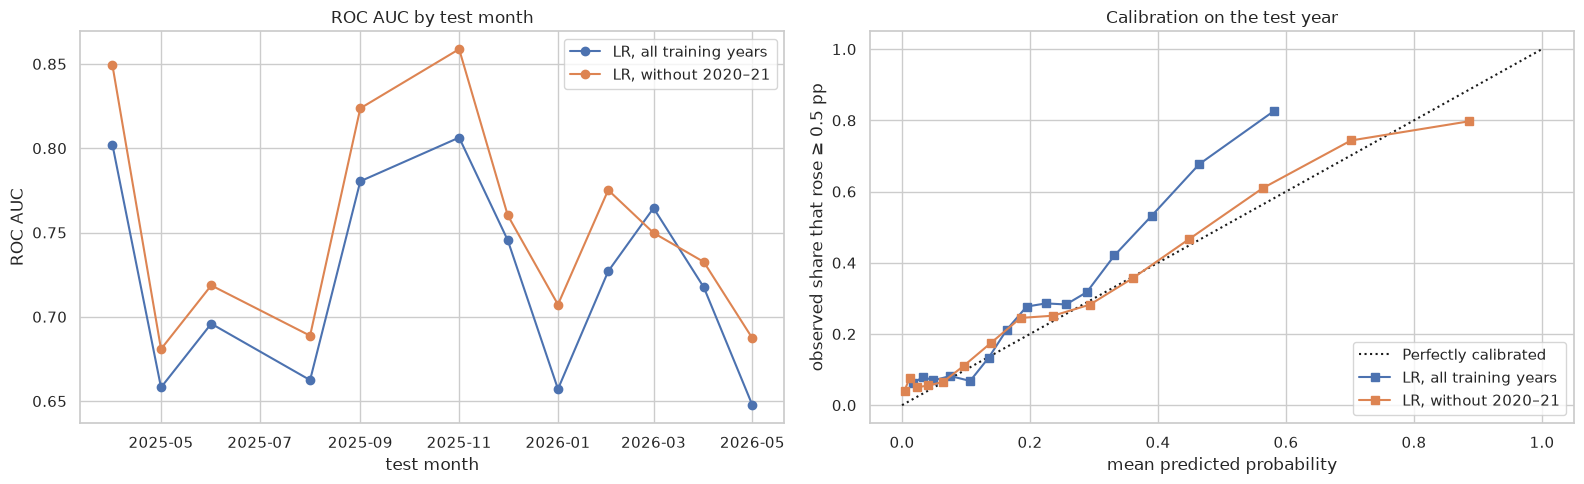

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for name in (A, B):
    pm = test.assign(p=probs[name]).groupby("month").apply(lambda g: roc_auc_score(g.y, g.p), include_groups=False)
    axes[0].plot(pm.index, pm.values, marker="o", label=name)
axes[0].set_xlabel("test month"); axes[0].set_ylabel("ROC AUC"); axes[0].set_title("ROC AUC by test month"); axes[0].legend()
for name in (A, B):
    CalibrationDisplay.from_predictions(y_test, probs[name], n_bins=15, strategy="quantile", name=name, ax=axes[1])
axes[1].set_xlabel("mean predicted probability"); axes[1].set_ylabel("observed share that rose ≥ 0.5 pp")
axes[1].set_title("Calibration on the test year"); plt.tight_layout(); plt.show()

## 4. The decision

> **Best model: logistic regression (elastic net, ρ = 0.25, C = 0.1) on the 26 `f_` mart features, trained without 2020–21,
> flagging a county when its score is ≥ 0.365** (the F1-optimal threshold from out-of-fold predictions on the tuning sample).

_Numbers from the run on 2026-10-24 (test year 2025-04 to 2026-05, positive rate 0.288)._

**Why this one**
1. **It wins every test-year metric among the usable models**, and the wins are real. Against the same LR trained on all years:
   ROC AUC **0.827 vs. 0.799**, PR AUC 0.668 vs. 0.643, log loss **0.464 vs. 0.498**, F1 **0.633 vs. 0.591**, precision 0.627 vs. 0.596,
   recall 0.640 vs. 0.586. The county-clustered bootstrap puts every difference clearly away from zero (ROC AUC +0.028, 95% CI
   +0.026 to +0.031; F1 +0.043, CI +0.037 to +0.048).
2. **It's consistently better, not better on average only.** It has the higher ROC AUC in 11 of the 12 test months (§3.2).
3. **Its scores can be read as probabilities.** On the calibration plot it tracks the diagonal. The all-years model *under*-predicts
   its riskiest counties (counties it scores around 0.45 actually rise about two-thirds of the time). The map shows scores, so this matters.
4. **Why dropping 2020–21 helps.** In 2020 almost every county jumped at once, then fell. Those months teach the model that huge
   national swings drive everything, which distorts the coefficients for normal years. Without them, the model learns the patterns that
   actually repeat.
5. **Why logistic regression at all.** Every SVM in notebook 02 scored significantly *below* LR on the test year, cost minutes to hours to
   fit, and needed a separate calibration step to produce probabilities. LR fits in about a minute, produces probabilities directly,
   has one interpretable coefficient per feature, and would be simple to retrain every 6 months.

## 5. Caveats and where to improve

**Caveats (read these before trusting a red county)**
- **On hard red/not-red flags, it still doesn't beat the seasonal-naive rule.** "Flag if this county rose ≥ 0.5 pp over the same window
  last year" gets F1 **0.667** and accuracy 0.794, versus 0.633 and 0.786 for this model. The model's advantages are a *ranked probability
  for every county* (the rule gives only yes/no, and it's missing for about 9% of rows) and better recall-precision control through the
  threshold. But for the flag alone, the rule is about as good. The first improvement below fixes this.
- **It has never seen a pandemic.** Dropping 2020–21 makes normal years better, but in a sudden nationwide shock its scores could come out
  too low. The FRED features (claims, payrolls) would still move, but treat a sudden national spike with
  extra caution.
- **One test year, one regime.** 2025–26 is a single economic period. The bootstrap measures noise *within* that year, not how a different
  year would go.
- **Hyperparameters weren't retuned for the no-COVID rows.** C and ρ come from notebook 01's search, which included 2020–21. All penalties
  tied within noise there, so the expected effect is small.
- **Data caveats carried from notebook 01:** training labels are *revised* LAUS history while real-time use would see *preliminary* data;
  county rates aren't seasonally adjusted; October 2025 has no county rate (so July and October 2025 have no label); and because of the
  publication lag, part of each 3-month window has already passed when a score appears.
- **The threshold weighs misses and false alarms equally** (F1). If a missed rise costs more than a false alarm, lower it.

**Where to improve, in order of expected payoff**
1. **Add the county's own seasonal history to the mart.** `rate(t−9) − rate(t−12)` and `rate(t−21) − rate(t−24)` as two new `f_` columns
   in `county_month`. In notebook 02 this lifted LR to ROC AUC **0.861** and F1 **0.68**, the first model to beat the seasonal-naive rule.
   It's a small dbt change (two `lag()` columns), after which this notebook can be rerun on the new features.
2. **Gradient-boosted trees**, which can learn county × season interactions directly. Judge them on the out-of-time test year, since CV
   flatters flexible models.
3. **Tune on a later period** (an out-of-time tuning year) so the hyperparameters and threshold are chosen the way the model is used:
   past predicting future (see notebook 01 §3.1).
4. **Down-weight 2020–21 instead of dropping it**, so the model keeps some memory of a nationwide shock.
5. **Test on preliminary data.** All results here use revised LAUS history. The raw tables keep every monthly snapshot, so after a few
   months the model can be re-checked on the first-published numbers it would actually see in real time.

## 6. Conclusions across the three notebooks

**What the data says (notebook 01).** The target is about 27–29% positive and strongly **seasonal**: county rates aren't seasonally
adjusted, so the same counties rise at the same time every year. 2020 is an extreme outlier. A careful validation design (an
out-of-time test year with a 3-month gap, and quarter-grouped folds) matters more than any model choice: cross-validation inside the
training years was consistently optimistic (CV ROC AUC 0.842 vs. 0.799 on the test year).

**What the models say (notebooks 01 and 02).**
- Regularization type barely matters for logistic regression (L1, L2, and elastic net all land at C = 0.1, within noise).
- PCA and UMAP hurt: the signal partly lives in low-variance directions, and UMAP doesn't transfer to new months.
- No SVM kernel beats logistic regression on the test year, even though kernels looked better in CV. Flexible models gain the most from
  CV's optimism and lose it on the future.
- The two changes that helped every model were **about the data, not the model**: dropping 2020–21 from training, and giving each county
  its own seasonal history.

**The final answer (this notebook).** Among models built only from the mart, the best is **logistic regression (elastic net,
ρ = 0.25, C = 0.1) trained without 2020–21, with a threshold of 0.365**: test ROC AUC 0.827, F1 0.633, well calibrated, and better than
the all-years model in 11 of 12 test months. Its main weakness is that it still doesn't beat the seasonal-naive rule on hard flags.

**The single most valuable next step** is adding the county's same-window change from 1 and 2 years ago to the mart. In notebook 02 that
was the only change that beat the seasonal-naive rule (ROC AUC 0.861, F1 0.68).